In [1]:
import intake
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import joblib
import os
from pathlib import Path
import gsw

import config
from utils.data import load_dataset
from utils.gridding import df_to_gridded_da
from utils.plotting import plot_geo_panels, generate_animation

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# Setup
data = load_dataset()
lat_min, lat_max = data.LATITUDE.min(), data.LATITUDE.max()
lon_min, lon_max = data.LONGITUDE.min(), data.LONGITUDE.max()
depths = np.sort(data.LEV_M.unique())
depths = np.append(depths, 5000)
times = np.sort(data.DATEANDTIME.unique())
times = np.append(times, 2021)
min_year = 1852
max_year = 2011

var_ids = ["thetao", "so", "o2", "no3", "si", "po4"]
param_map = {"thetao": "P_TEMPERATURE",
             "so": "P_SALINITY",
             "o2": "P_OXYGEN",
             "no3": "P_NITRATE",
             "si": "P_SILICATE",
             "po4": "P_PHOSPHATE",
             }
param_map_r = {v: k for k, v in param_map.items()}
all_model_names = ["mean", "knn", "missforest", "mlp", "remasker", "mastnet"]

# CMIP download and preparation

In [ ]:
# Downloads GFDL-ESM4 historical run from the pangeo-cmip6 cloud store and saves pre-processed parquets to ../../data/cmip_data/
# Skip if parquets already exist on disk

cat_url = "https://storage.googleapis.com/cmip6/pangeo-cmip6.json"
col = intake.open_esm_datastore(cat_url)
os.makedirs("../../data/cmip_data/", exist_ok=True)

In [ ]:
# Unit conversion: mol m-3 -> umol/kg using per-cell in-situ density (gsw)
# Evaluated on native grid BEFORE depth/time binning to avoid nonlinearity bias
NO_CONVERT = ["thetao", "so"]  # degC and practical salinity: leave as-is
CONC_VARS = ["o2", "no3", "si", "po4"]


def load_native_filtered(col, var_id, lat_min, lat_max, lon_min, lon_max):
    cat = col.search(experiment_id=["historical"], variable_id=[var_id],
                     source_id=["GFDL-ESM4"], table_id=["Omon"], grid_label=["gr"])
    dset_dict = cat.to_dataset_dict(zarr_kwargs={"use_cftime": True})
    ds = dset_dict["CMIP.NOAA-GFDL.GFDL-ESM4.historical.Omon.gr"]
    da = ds[var_id].squeeze()
    da = da.assign_coords(lon=(((da.lon + 180) % 360) - 180)).sortby("lon")
    return da.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))


thetao = load_native_filtered(col, "thetao", lat_min, lat_max, lon_min, lon_max)
so = load_native_filtered(col, "so", lat_min, lat_max, lon_min, lon_max)
z = -thetao["lev"]
p = gsw.p_from_z(z, thetao["lat"])
SA = gsw.SA_from_SP(so, p, so["lon"], so["lat"])
CT = gsw.CT_from_pt(SA, thetao)
rho = gsw.rho(SA, CT, p).rename("rho_insitu")


def molm3_to_umolkg(da_conc, rho_insitu):
    return da_conc * 1e6 / rho_insitu

In [ ]:
# Bin to custom depth/time grid and save as parquet
cmip_dict = {}
for var_id, param in zip(var_ids, config.parameters):
    print(var_id, param)
    if var_id in NO_CONVERT:
        da = load_native_filtered(col, var_id, lat_min, lat_max, lon_min, lon_max)
    else:
        da_native = load_native_filtered(col, var_id, lat_min, lat_max, lon_min, lon_max)
        da = molm3_to_umolkg(da_native, rho)

    depth_avg = da.groupby_bins("lev", depths).mean()
    depth_avg = depth_avg.assign_coords({"lev_bins": depths[:-1]})
    years = depth_avg["time"].dt.year.data
    depth_avg = depth_avg.assign_coords(year=("time", years))
    depth_avg = depth_avg.where(
        (depth_avg["year"] >= min_year) & (depth_avg["year"] <= max_year), drop=True)
    time_avg = depth_avg.groupby_bins("year", bins=times, include_lowest=True, right=False).mean()
    time_avg = time_avg.assign_coords({"year_bins": times[:-1]})

    df_cmip = time_avg.to_dataframe(name=var_id).dropna(subset=[var_id]).reset_index()
    df_cmip["lat_round"] = df_cmip["lat"].round(1)
    df_cmip["lon_round"] = df_cmip["lon"].round(1)
    df_cmip.to_parquet(f"../../data/cmip_data/cmip_{param}.parquet")
    cmip_dict[param] = df_cmip

# Load pre-processed CMIP

In [3]:
# Entry point for analysis runs (loads from pre-saved parquets)
cmip_dict = {}
for param in config.parameters:
    cmip_dict[param] = pd.read_parquet(f"../../data/cmip_data/cmip_{param}.parquet")

In [ ]:
# Optional: Animations of CMIP fields
for param, df_temp in cmip_dict.items():
    df_temp = df_temp.rename(columns={"year_bins": "DATEANDTIME", "lev_bins": "LEV_M",
                                      "lat_round": "LATITUDE", "lon_round": "LONGITUDE"})
    df_temp = df_temp[config.coordinates + [param_map_r[param]]]

    generate_animation(df_temp, scaler_dict=None, parameter=param_map_r[param],
                       save_as=f"../../data/cmip_data/cmip_{param}.mp4")

# Compute CMIP differences

In [4]:
def summarise_cmip_diff(df_rec, df_true, cmip_dict, model_name, model_out_dir, scaler_dict=None, do_animation=True):
    # scaler_dict=None : physical (unscaled) units
    # scaler_dict=...  : normalised [0,1] space
    suffix = "_scaled" if scaler_dict is not None else ""
    diff_summary = []
    df_compares = []

    for var_id, parameter in zip(var_ids, config.parameters):
        temp_cmip = cmip_dict[parameter].copy()
        if scaler_dict is not None and parameter in scaler_dict:
            temp_cmip[var_id] = scaler_dict[parameter].transform(
                temp_cmip[var_id].to_numpy().reshape(-1, 1))

        df_rec["lat_round"] = df_rec["LATITUDE"].round(1)
        df_rec["lon_round"] = df_rec["LONGITUDE"].round(1)
        df_rec["was_missing"] = df_true[parameter].isna().values
        df_missing = df_rec[df_rec["was_missing"] & (df_rec["DATEANDTIME"] >= min_year)]

        df_compare = df_missing.merge(
            temp_cmip,
            left_on=["DATEANDTIME", "lat_round", "lon_round", "LEV_M"],
            right_on=["year_bins", "lat_round", "lon_round", "lev_bins"],
            how="inner")
        df_compare["diff"] = df_compare[parameter] - df_compare[var_id]
        df_compares.append(df_compare)

        # Animation of spatial diff field
        if do_animation:
            absmax = df_compare["diff"].abs().max()
            norm = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)
            generate_animation(df_compare, scaler_dict=None, parameter="diff",
                               save_as=f"{model_out_dir}/{model_name}_cmip_diff_{parameter}{suffix}.mp4",
                               cmap="seismic", norm=norm)
            plt.close()

        diff_summary.append(pd.DataFrame({
            "parameter": [parameter],
            "MAE": [df_compare["diff"].abs().mean()],
            "std": [df_compare["diff"].abs().std()],
        }))

    pd.concat(diff_summary).to_csv(
        f"{model_out_dir}/{model_name}_cmip_diff_summary{suffix}.csv", index=False)
    pd.concat(df_compares).to_csv(
        f"{model_out_dir}/{model_name}_cmip_diff{suffix}.csv", index=False)
    return pd.concat(diff_summary)

In [ ]:
# Final test models
for model_name in all_model_names:

    # # Ablation experiments
    # for model_dir in sorted(Path(config.output_dir_tuning + "/mastnet/architecture_ablation").glob("exp*/")):
    #     model_name  = "mastnet"

    # Data paths
    model_dir = Path("output/testing") / model_name
    y_pred_file = model_dir / f"model{model_name}_y_pred.csv"
    y_true_file = model_dir / f"model{model_name}_y_true.csv"
    if not y_pred_file.exists():
        print(f"Skipping {model_name}: no predictions found")
        continue

    # Load ground truth and predictions
    y_pred = pd.read_csv(y_pred_file)
    y_true = pd.read_csv(y_true_file)
    for c in ["Unnamed: 0"]:
        if c in y_pred.columns: y_pred = y_pred.drop(c, axis=1)
        if c in y_true.columns: y_true = y_true.drop(c, axis=1)

    # Unscale predictions
    scalers = joblib.load(model_dir / "scalers.joblib")
    y_pred_unscaled = y_pred.copy()
    for k, v in scalers.items():
        if k in y_pred_unscaled.columns:
            y_pred_unscaled[k] = v.inverse_transform(
                y_pred_unscaled[k].to_numpy().reshape(-1, 1))

    # Add coordinates
    y_pred_unscaled[config.coordinates] = data[config.coordinates].values
    y_true[config.coordinates] = data[config.coordinates].values

    y_pred_scaled = y_pred.copy()
    y_pred_scaled[config.coordinates] = data[config.coordinates].values

    print(f"Computing CMIP diffs: {model_name}")
    summarise_cmip_diff(df_rec=y_pred_unscaled.copy(), df_true=y_true,
                        cmip_dict=cmip_dict, model_name=model_name,
                        model_out_dir=model_dir, scaler_dict=None,
                        do_animation=False)
    summarise_cmip_diff(df_rec=y_pred_scaled.copy(), df_true=y_true,
                        cmip_dict=cmip_dict, model_name=model_name,
                        model_out_dir=model_dir, scaler_dict=scalers,
                        do_animation=False)


In [5]:
def compute_cmip_diffs(df_rec, df_true, cmip_dict, scaler_dict=None):
    """
    Spatial mean and std of (prediction - CMIP) per (lat, lon, depth) location.

    Processes one parameter at a time and frees intermediate DataFrames
    immediately to keep peak memory well below the full-dataset footprint.

    Returns {"mean": DataFrame, "std": DataFrame} with columns
    LATITUDE, LONGITUDE, LEV_M, P_TEMPERATURE, P_SALINITY, ...
    """
    mean_series = []
    std_series = []

    for var_id, parameter in zip(var_ids, config.parameters):
        # Load only the CMIP columns needed for the merge — avoids copying all metadata
        cmip_cols = ["lat_round", "lon_round", "lev_bins", "year_bins", var_id]
        temp_cmip = cmip_dict[parameter][cmip_cols].copy()

        # Optionally scale CMIP into the same [0,1] space as the model predictions
        if scaler_dict is not None and parameter in scaler_dict:
            temp_cmip[var_id] = scaler_dict[parameter].transform(
                temp_cmip[var_id].to_numpy().reshape(-1, 1))

        # Restrict to positions that were missing in the observations
        missing_mask = df_true[parameter].isna().values
        cols = ["LATITUDE", "LONGITUDE", "LEV_M", "DATEANDTIME", parameter]
        df_miss = df_rec.loc[missing_mask, cols].copy()  # small subset, only needed cols
        df_miss = df_miss[df_miss["DATEANDTIME"] >= min_year]
        df_miss["lat_round"] = df_miss["LATITUDE"].round(1)
        df_miss["lon_round"] = df_miss["LONGITUDE"].round(1)
        # Cast to int to match year_bins dtype
        df_miss["DATEANDTIME"] = df_miss["DATEANDTIME"].astype(int)

        # Match imputed predictions to the corresponding CMIP grid cell and time bin
        df_cmp = df_miss.merge(
            temp_cmip,
            left_on=["DATEANDTIME", "lat_round", "lon_round", "LEV_M"],
            right_on=["year_bins", "lat_round", "lon_round", "lev_bins"],
            how="inner")
        del df_miss, temp_cmip  # free large intermediate frames immediately

        df_cmp["diff"] = df_cmp[parameter] - df_cmp[var_id]

        # Spatially aggregate: average the signed difference over time at each location
        grp = df_cmp.groupby(["LATITUDE", "LONGITUDE", "LEV_M"])["diff"]
        mean_series.append(grp.mean().rename(parameter))
        std_series.append(grp.std().rename(parameter))
        del df_cmp

    # Each series is indexed by (LATITUDE, LONGITUDE, LEV_M) — concat aligns them
    df_mean = pd.concat(mean_series, axis=1).reset_index()
    df_std = pd.concat(std_series, axis=1).reset_index()
    return {"mean": df_mean, "std": df_std}


def compute_cmip_trend(df_rec, df_true, cmip_dict, scaler_dict=None):
    """
    Signed mean difference (prediction - CMIP) grouped by year.

    Returns a DataFrame with columns: DATEANDTIME, diff, std, parameter.
    diff is the spatial mean across all matched locations at that year;
    std is the spatial spread / how consistent the bias is across space.
    """
    rows = []

    for var_id, parameter in zip(var_ids, config.parameters):
        cmip_cols = ["lat_round", "lon_round", "lev_bins", "year_bins", var_id]
        temp_cmip = cmip_dict[parameter][cmip_cols].copy()

        if scaler_dict is not None and parameter in scaler_dict:
            temp_cmip[var_id] = scaler_dict[parameter].transform(
                temp_cmip[var_id].to_numpy().reshape(-1, 1))

        missing_mask = df_true[parameter].isna().values
        cols = ["LATITUDE", "LONGITUDE", "LEV_M", "DATEANDTIME", parameter]
        df_miss = df_rec.loc[missing_mask, cols].copy()
        df_miss = df_miss[df_miss["DATEANDTIME"] >= min_year]
        df_miss["lat_round"] = df_miss["LATITUDE"].round(1)
        df_miss["lon_round"] = df_miss["LONGITUDE"].round(1)
        df_miss["DATEANDTIME"] = df_miss["DATEANDTIME"].astype(int)

        df_cmp = df_miss.merge(
            temp_cmip,
            left_on=["DATEANDTIME", "lat_round", "lon_round", "LEV_M"],
            right_on=["year_bins", "lat_round", "lon_round", "lev_bins"],
            how="inner")
        del df_miss, temp_cmip

        df_cmp["diff"] = df_cmp[parameter] - df_cmp[var_id]

        # Temporal aggregate: collapse spatial variation into mean ± std per year
        grp = df_cmp.groupby("DATEANDTIME")["diff"]
        t = grp.mean().reset_index()
        t["std"] = grp.std().values
        t["parameter"] = parameter
        rows.append(t)
        del df_cmp

    return pd.concat(rows, ignore_index=True)

In [6]:
# CMIP differences per grid cell
depths_map = [0, 200, 1000]
models_to_plot = [m for m in all_model_names if m != "mean"]

res_cmip_unscaled = {}  # spatial mean/std of (pred - CMIP) in physical units
res_cmip_scaled = {}  # same in normalised [0,1] space
trend_data_unscaled = {}  # temporal mean/std of (pred - CMIP) by year, physical units
trend_data = {}  # same in normalised [0,1] space

for model_name in models_to_plot:
    print(f"Processing {model_name}...")
    model_dir = Path("output/testing") / model_name
    y_pred = pd.read_csv(model_dir / f"model{model_name}_y_pred.csv")
    y_true_raw = pd.read_csv(model_dir / f"model{model_name}_y_true.csv")

    # Clean up
    for c in ["Unnamed: 0"]:
        if c in y_pred.columns:     y_pred = y_pred.drop(c, axis=1)
        if c in y_true_raw.columns: y_true_raw = y_true_raw.drop(c, axis=1)

    # Unscale features
    scalers = joblib.load(model_dir / "scalers.joblib")
    y_pred_unscaled = y_pred.copy()
    for k, v in scalers.items():
        if k in y_pred_unscaled.columns:
            y_pred_unscaled[k] = v.inverse_transform(
                y_pred_unscaled[k].to_numpy().reshape(-1, 1))

    # Attach spatial and temporal coordinates after unscaling
    y_pred[config.coordinates] = data[config.coordinates].values
    y_pred_unscaled[config.coordinates] = data[config.coordinates].values
    y_true_raw[config.coordinates] = data[config.coordinates].values

    # Compute diffs (unscaled/physical units)
    res_cmip_unscaled[model_name] = compute_cmip_diffs(
        df_rec=y_pred_unscaled, df_true=y_true_raw, cmip_dict=cmip_dict)
    # Temporal trend in physical units
    trend_data_unscaled[model_name] = compute_cmip_trend(
        df_rec=y_pred_unscaled, df_true=y_true_raw, cmip_dict=cmip_dict)
    del y_pred_unscaled

    # Compute diffs (scaled)
    res_cmip_scaled[model_name] = compute_cmip_diffs(
        df_rec=y_pred, df_true=y_true_raw, cmip_dict=cmip_dict, scaler_dict=scalers)
    trend_data[model_name] = compute_cmip_trend(
        df_rec=y_pred, df_true=y_true_raw, cmip_dict=cmip_dict, scaler_dict=scalers)
    del y_pred, y_true_raw
    print(f"  Done.")

Processing knn...


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations



  Done.
Processing missforest...


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations



  Done.
Processing mlp...


...

  Done.
Processing remasker...


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations



  Done.
Processing mastnet...


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations



  Done.


# Difference maps (per feature, physical units)

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_unscaled_P_TEMPERATURE.png


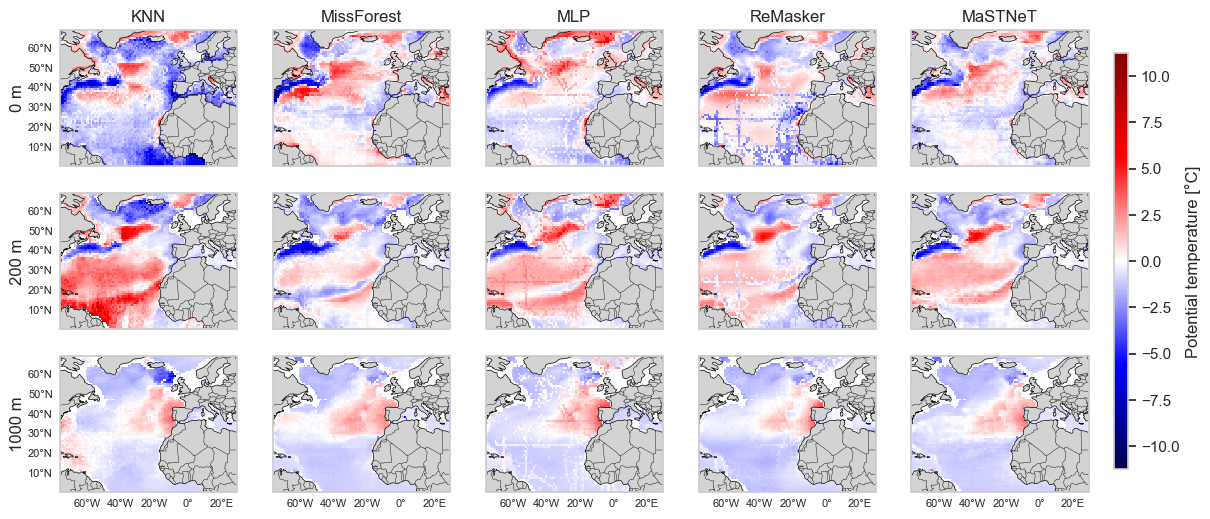

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_unscaled_P_SALINITY.png


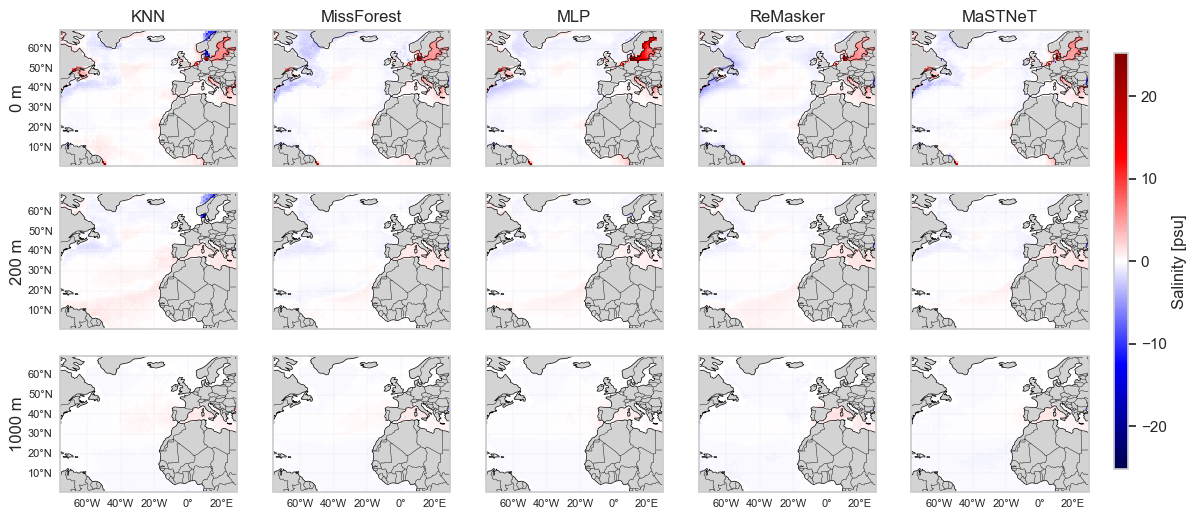

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_unscaled_P_OXYGEN.png


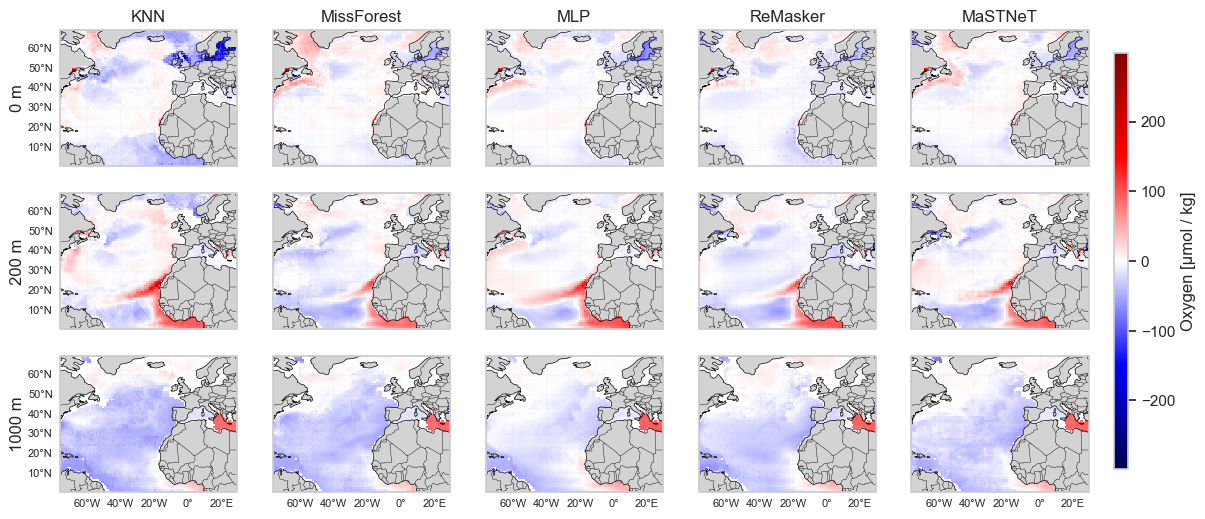

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_unscaled_P_NITRATE.png


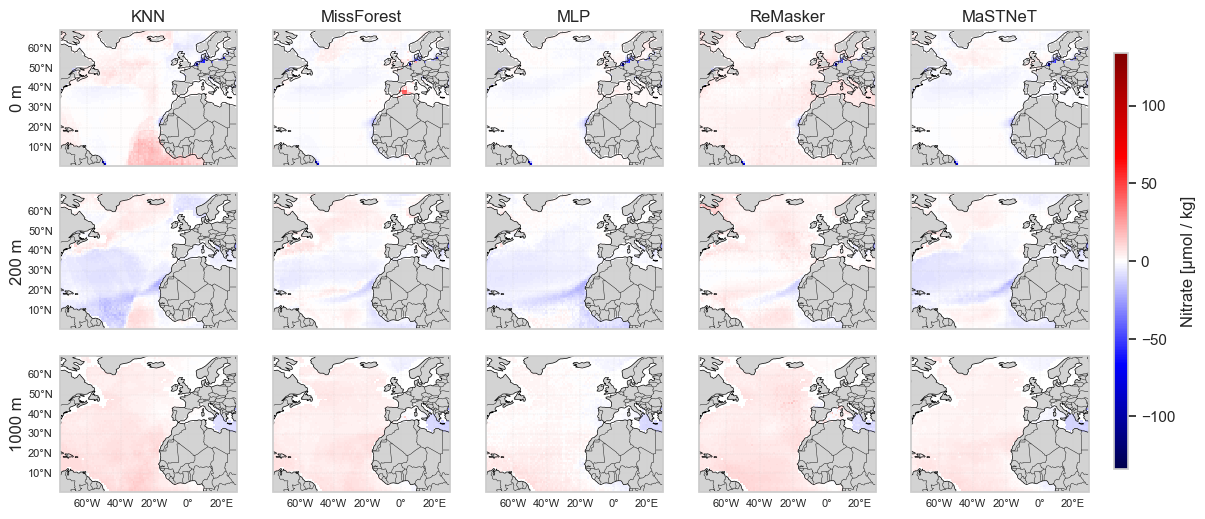

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_unscaled_P_SILICATE.png


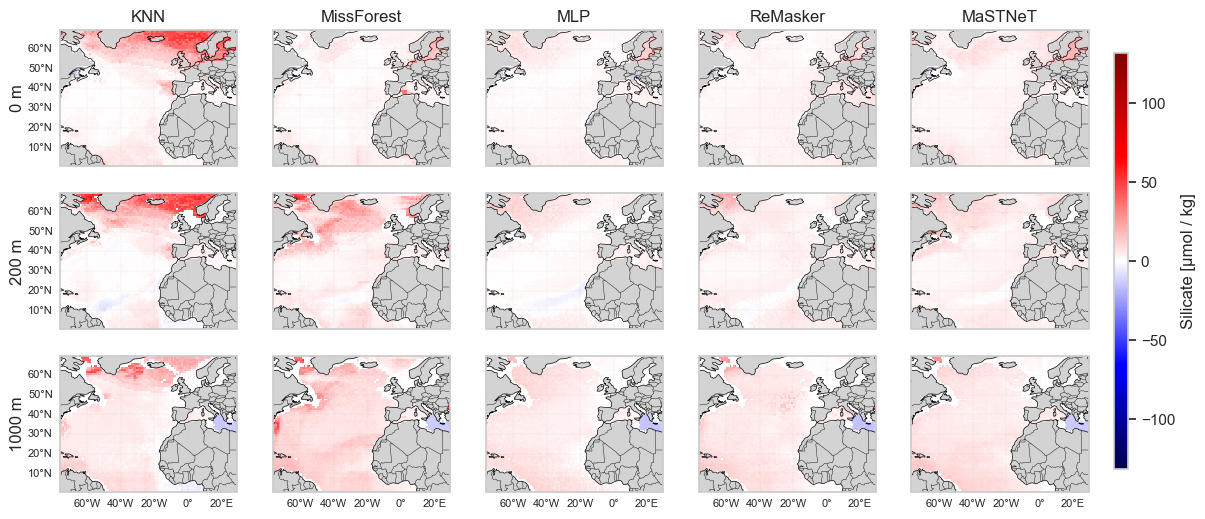

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_unscaled_P_PHOSPHATE.png


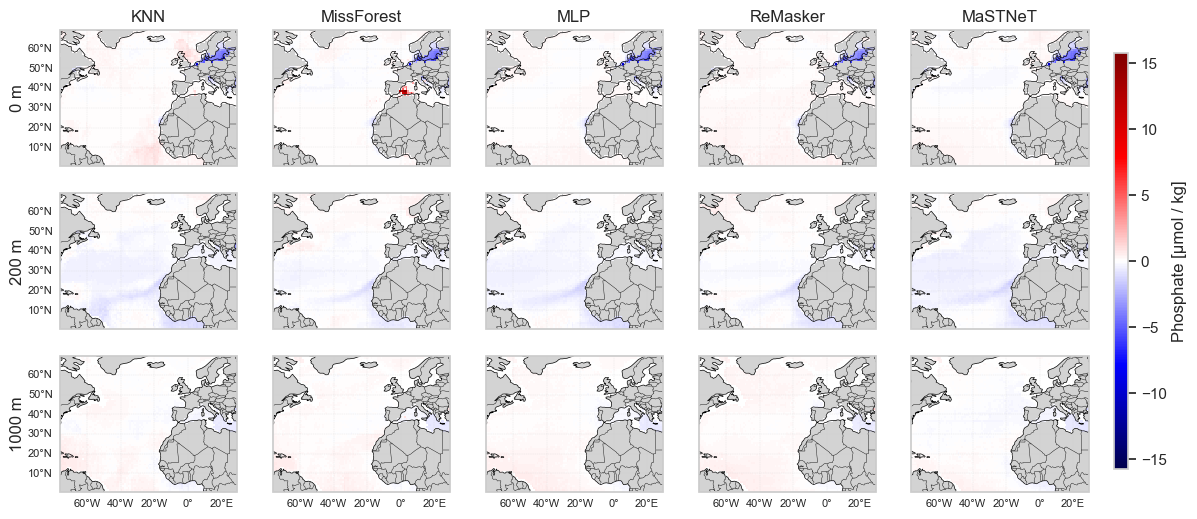

In [7]:
# Map of mean(pred-CMIP) at 3 depth levels
sns.set_theme(style="whitegrid")
os.makedirs("output/plots/cmip6_comparison/diff_maps/", exist_ok=True)

for parameter in config.parameters:
    # Symmetric colour bounds: same absmax across all models
    absmax = max(
        res_cmip_unscaled[m]["mean"][parameter].abs().max()
        for m in models_to_plot
        if parameter in res_cmip_unscaled[m]["mean"].columns
    )
    # Centres colourmap at zero
    norm = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

    # Assemble dict {model_name: mean_diff as xarray}
    gridded = {
        m: df_to_gridded_da(
            res_cmip_unscaled[m]["mean"][
                res_cmip_unscaled[m]["mean"]["LEV_M"].isin(depths_map)],
            value_col=parameter
        )
        for m in models_to_plot
    }

    # Plot
    plot_geo_panels(
        get_data=lambda d, m, _g=gridded: _g[m].sel(depth=d),
        row_items=[(d, f"{d} m") for d in depths_map],
        col_items=[(m, config.model_name_map.get(m, m)) for m in models_to_plot],
        plot_config={"cmap": "seismic", "norm": norm},
        colorbar_label=config.parameter_name_unit_map.get(parameter, parameter),
        output_path="output/plots/cmip6_comparison/diff_maps/",
        filename=f"cmip_diff_unscaled_{parameter}.png",
        dpi=300,
    )

Saved: output/plots/cmip6_comparison/diff_maps//cmip_diff_scaled_mean_features.png


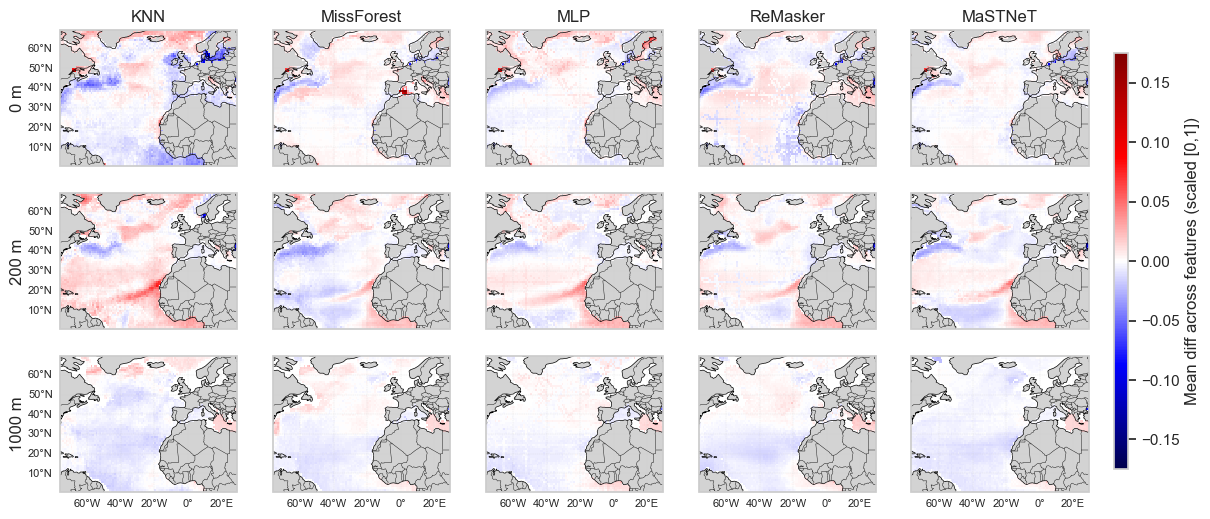

In [8]:
# Average signed difference across all parameters
for mode in ["mean", "std"]:
    for m in models_to_plot:
        df_m = res_cmip_scaled[m][mode].copy()
        df_m["mean_diff"] = df_m[config.parameters].mean(axis=1)  # cross-feature mean
        res_cmip_scaled[m][f"avg_{mode}"] = df_m[df_m["LEV_M"].isin(depths_map)]

# Symmetric bounds shared across models
absmax_scaled = max(
    res_cmip_scaled[m]["avg_mean"]["mean_diff"].abs().max()
    for m in models_to_plot
)
norm_scaled = mcolors.TwoSlopeNorm(vmin=-absmax_scaled, vcenter=0, vmax=absmax_scaled)

# Assemble dict {model_name: mean_diff as xarray}
gridded_avg = {
    m: df_to_gridded_da(res_cmip_scaled[m]["avg_mean"], value_col="mean_diff")
    for m in models_to_plot
}

# Plot
plot_geo_panels(
    get_data=lambda d, m, _g=gridded_avg: _g[m].sel(depth=d),
    row_items=[(d, f"{d} m") for d in depths_map],
    col_items=[(m, config.model_name_map.get(m, m)) for m in models_to_plot],
    plot_config={"cmap": "seismic", "norm": norm_scaled},
    colorbar_label="Mean diff across features (scaled [0,1])",
    output_path="output/plots/cmip6_comparison/diff_maps/",
    filename="cmip_diff_scaled_mean_features.png",
    dpi=300,
)

# Summary comparison

In [9]:
# Load summary CSVs written by summarise_cmip_diff
summary_rows = []
for model_name in all_model_names:
    csv_path = Path("output/testing") / model_name / f"{model_name}_cmip_diff_summary_scaled.csv"
    if csv_path.exists():
        df_s = pd.read_csv(csv_path)
        df_s["Model"] = config.model_name_map.get(model_name, model_name)
        summary_rows.append(df_s)
    else:
        print(f"Missing: {csv_path}")

summary = pd.concat(summary_rows, ignore_index=True)
summary["parameter"] = summary["parameter"].map(config.parameter_name_map)

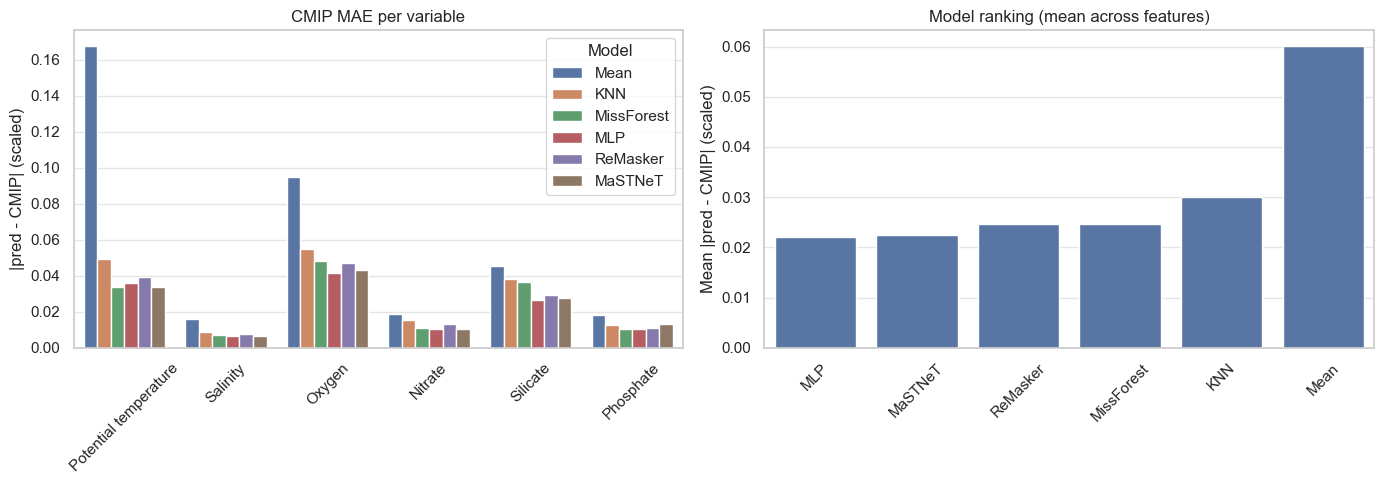

In [10]:
# Diffs to CMIP overall and per feature
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Per-feature MAE
sns.barplot(data=summary, x="parameter", y="MAE", hue="Model", ax=axes[0])
axes[0].set_xlabel("")
axes[0].set_ylabel("|pred - CMIP| (scaled)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("CMIP MAE per variable")

# Mean across features
mean_mae = summary.groupby("Model")["MAE"].mean().sort_values().reset_index()
sns.barplot(data=mean_mae, x="Model", y="MAE", ax=axes[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean |pred - CMIP| (scaled)")
axes[1].set_title("Model ranking (mean across features)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
os.makedirs("output/plots/cmip6_comparison/", exist_ok=True)
plt.savefig("output/plots/cmip6_comparison/cmip_mae_summary.png", dpi=300)
plt.show()

# Temporal trend analysis

In [11]:
# Assemble long-format trend DataFrames (scaled and physical units)
trend_rows, trend_rows_unscaled = [], []
for model_name in models_to_plot:
    for df, rows in [(trend_data[model_name], trend_rows),
                     (trend_data_unscaled[model_name], trend_rows_unscaled)]:
        d = df.copy()
        d["Model"] = config.model_name_map.get(model_name, model_name)
        rows.append(d)
df_trend = pd.concat(trend_rows, ignore_index=True)
df_trend_unscaled = pd.concat(trend_rows_unscaled, ignore_index=True)

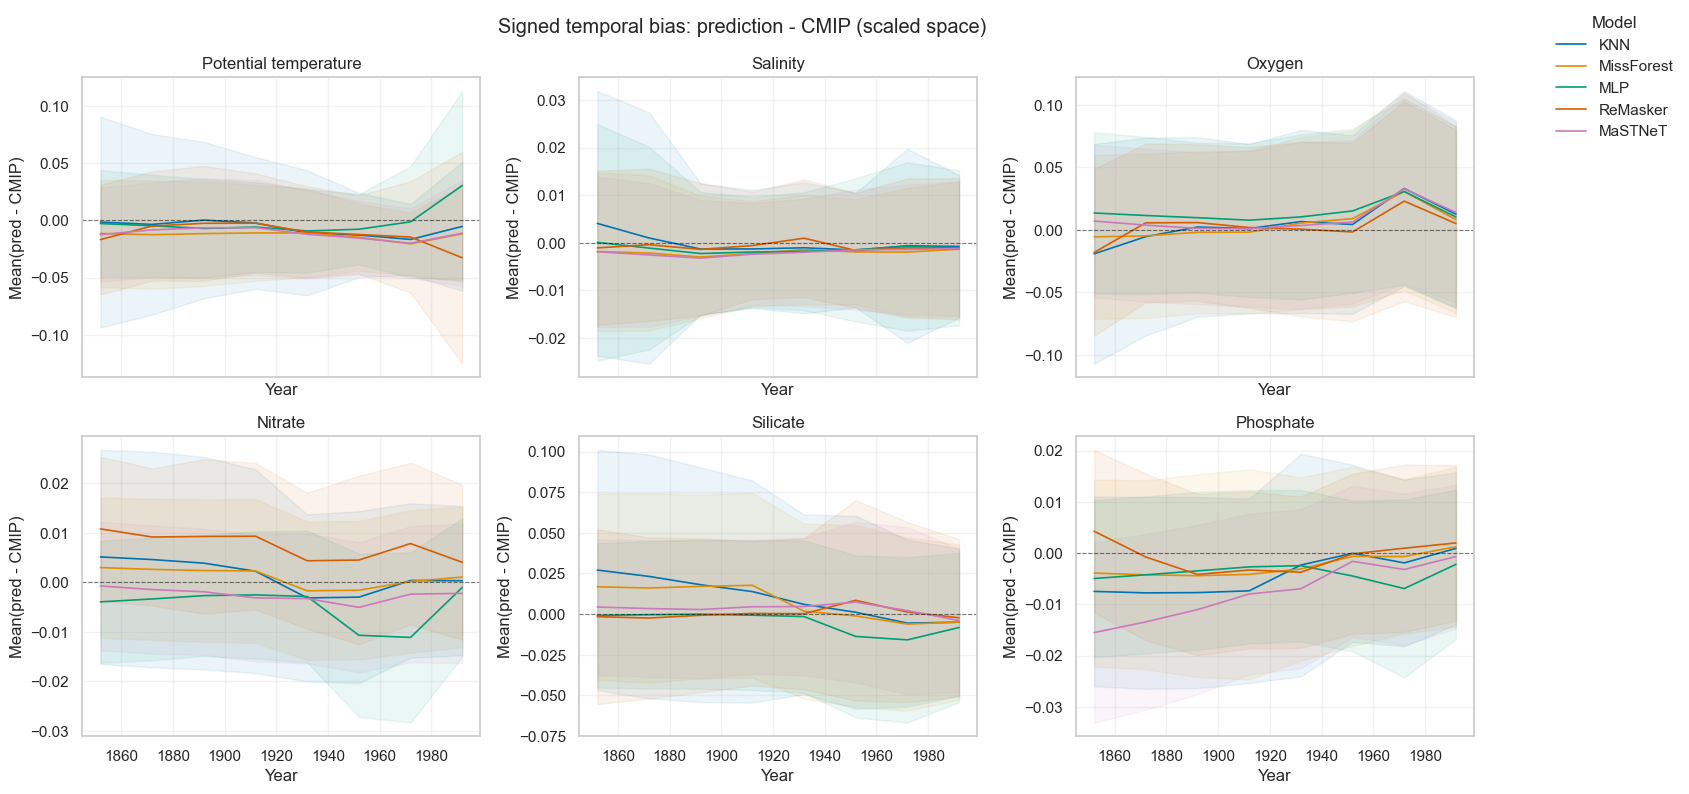

In [14]:
# SCALED Signed per-parameter bias (mean(pred-CMIP)) for every time bin
# Shading: +- standard deviation (across space)
palette = dict(zip(
    [config.model_name_map.get(m, m) for m in models_to_plot],
    sns.color_palette("colorblind", n_colors=len(models_to_plot))
))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.flatten()

# Iterate over parameters
for ax, param in zip(axes, config.parameters):
    # param_name = config.parameter_name_unit_map.get(param, param)
    param_name = config.parameter_name_map.get(param, param)
    df_p = df_trend[df_trend["parameter"] == param].sort_values("DATEANDTIME")

    # Iterate over models
    for model_label, color in palette.items():
        df_m = df_p[df_p["Model"] == model_label]
        ax.plot(df_m["DATEANDTIME"], df_m["diff"], label=model_label, color=color, linewidth=1.2)
        ax.fill_between(df_m["DATEANDTIME"],
                        df_m["diff"] - df_m["std"],
                        df_m["diff"] + df_m["std"],
                        alpha=0.08, color=color)

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
    ax.set_title(param_name)
    ax.set_xlabel("Year")
    ax.set_ylabel("Mean(pred - CMIP)")
    ax.grid(True, alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(1.13, 1), frameon=False, title="Model")
plt.suptitle("Signed temporal bias: prediction - CMIP (scaled space)")
plt.tight_layout()
plt.savefig("output/plots/cmip6_comparison/trend_signed_bias_scaled.png", dpi=300, bbox_inches="tight")
plt.show()

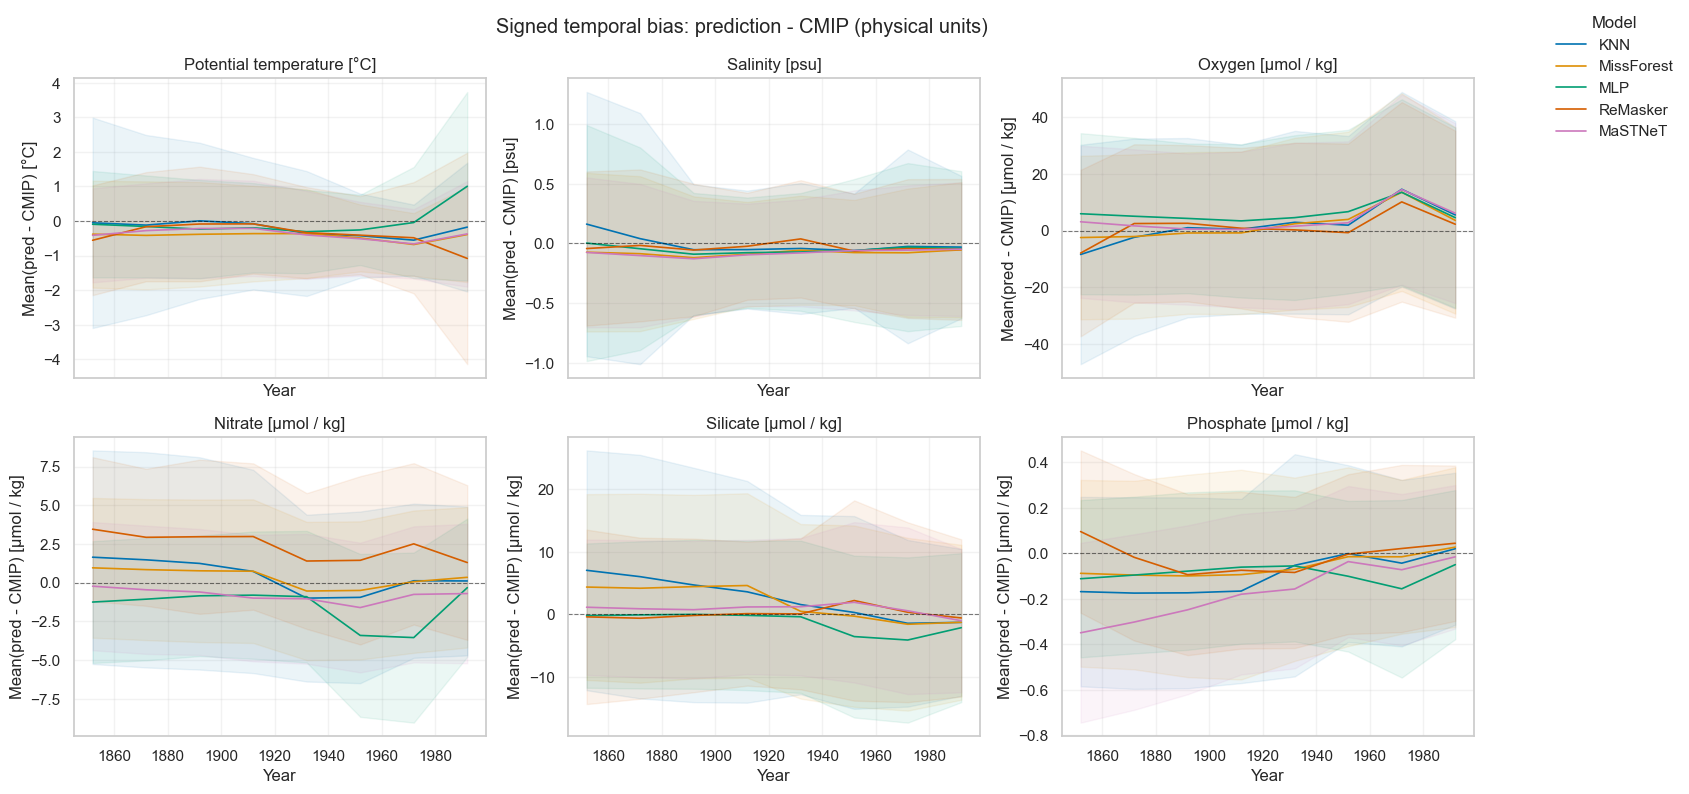

In [13]:
# UNSCALED Signed per-parameter bias (mean(pred-CMIP)) for every time bin
# Shading: +- standard deviation (across space)

palette = dict(zip(
    [config.model_name_map.get(m, m) for m in models_to_plot],
    sns.color_palette("colorblind", n_colors=len(models_to_plot))
))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.flatten()

# Iterate over parameters
for ax, param in zip(axes, config.parameters):
    param_name = config.parameter_name_unit_map.get(param, param)
    unit = param_name.split("[")[-1].rstrip("]") if "[" in param_name else ""
    df_p = df_trend_unscaled[df_trend_unscaled["parameter"] == param].sort_values("DATEANDTIME")

    # Iterate over models
    for model_label, color in palette.items():
        df_m = df_p[df_p["Model"] == model_label]
        ax.plot(df_m["DATEANDTIME"], df_m["diff"], label=model_label, color=color, linewidth=1.2)
        ax.fill_between(df_m["DATEANDTIME"],
                        df_m["diff"] - df_m["std"],
                        df_m["diff"] + df_m["std"],
                        alpha=0.08, color=color)

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
    ax.set_title(param_name)
    ax.set_xlabel("Year")
    ax.set_ylabel(f"Mean(pred - CMIP) [{unit}]")
    ax.grid(True, alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(1.13, 1), frameon=False, title="Model")
plt.suptitle("Signed temporal bias: prediction - CMIP (physical units)")
plt.tight_layout()
plt.savefig("output/plots/cmip6_comparison/trend_signed_bias_physical.png", dpi=300, bbox_inches="tight")
plt.show()